# Práctica N°03: Simulación de eventos discretos

# 5.1. Sistema de línea de espera con un servidor (G/G/1)

In [1]:
%matplotlib inline

import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
M = 99999.0

def gencongru1():
    global Xant1
    a = 134775813
    c = 1
    m = 2**32
    Xnext = (a * Xant1 + c) % m
    Xant1 = Xnext
    U = Xnext / m
    return U

def gencongru2():
    global Xant2
    a = 1140671485
    c = 12820163
    m = 2**24
    Xnext = (a * Xant2 + c) % m
    Xant2 = Xnext
    U = Xnext / m
    return U

def GenerarX():
    U = gencongru1()
    X = -(math.log(1-U))/float(vlambda_llegada)
    return X

def GenerarY():
    # servicio exponencial (escenario A) o normal truncada en 0 (escenario B)
    if servicio == 'exponencial':
        U = gencongru2()
        Y = -(math.log(1-U))/float(vlambda_servicio)
    else:
        Y = np.random.normal(mu_servicio, sigma_servicio)
        if Y < 0:
            Y = 0
    return Y

def Llegada(tsuc):
    global n, NLL, NS, t, S, Serv, LL, at, an
    t = tsuc
    n = n + 1
    LLt.append(t)
    at.append(t)
    an.append(n)

    NLL = NLL + 1
    LL.append(t)

    X = GenerarX()

    if (t+X) < T:
        TSuc['tLL'] = t + X
    if n==1:
        Y = GenerarY()
        TSuc['tS'] = t + Y
        Serv.append(Y)

def Servidor(tsuc):
    global n, NLL, NS, t, S, Serv, LL, at, an
    t = tsuc
    n = n - 1

    St.append(t)
    at.append(t)
    an.append(n)

    NS = NS + 1
    S.append(t)

    if n>0:
        Y = GenerarY()
        TSuc['tS'] = t + Y
        Serv.append(Y)

## Escenario A

T = 40 · tiempo entre llegadas ~ Exponencial(λ = 5) · tiempo de atención ~ Exponencial(λ = 3)

### Ejecución única

In [3]:
T = 40.0
vlambda_llegada = 5
servicio = 'exponencial'
vlambda_servicio = 3

Xant1 = 434287492
Xant2 = 5187324426

at = []
an = []
LLt = []
St = []

t = tsuc = NLL = NS = n = 0

at.append(t)
an.append(n)

TSuc = {"tLL":M, "tS":M}

LL = []
S = []
Serv = []
LL.append(0.0)
S.append(0.0)
Serv.append(0.0)

X = GenerarX()

if X > T:
    Tp = t_med_sistema = t_med_cola = 0.0
else:
    Llegada(X)
    while((TSuc['tLL'] != M)|(TSuc['tS']!=M)):
        if TSuc['tLL'] < TSuc['tS']:
            tsuc = TSuc['tLL']
            TSuc['tLL'] = M
            Llegada(tsuc)

        if TSuc['tS'] < TSuc['tLL']:
            tsuc = TSuc['tS']
            TSuc['tS'] = M
            Servidor(tsuc)

    Tp = max(0,t-T)
    acumulo1 = acumulo2 = 0.0
    ind = 1                      # modificado: LL, S y Serv tienen un 0.0 de relleno en el indice 0

    while ind <= NLL:            # modificado: incluye al ultimo cliente
        acumulo1 = acumulo1 + S[ind] - LL[ind]
        acumulo2 = acumulo2 + S[ind] - LL[ind] - Serv[ind]
        ind = ind + 1
    t_med_sistema = acumulo1/NLL
    t_med_cola = acumulo2/NLL

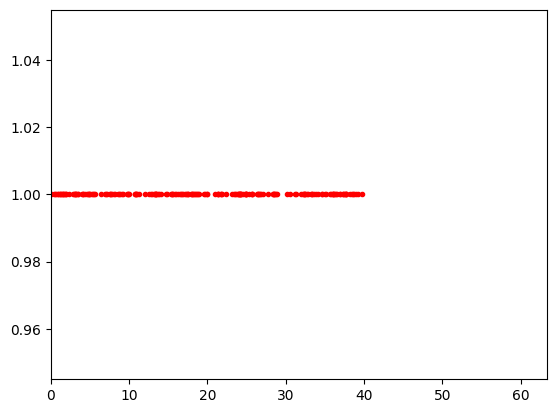

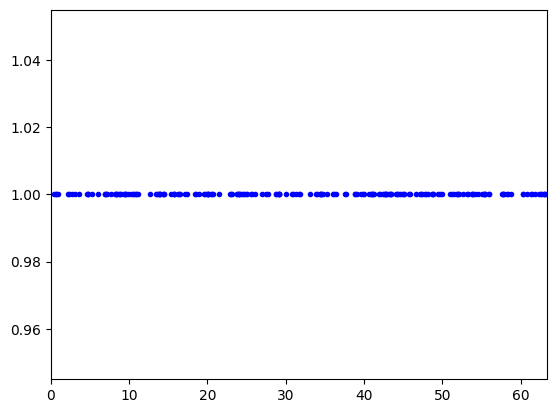

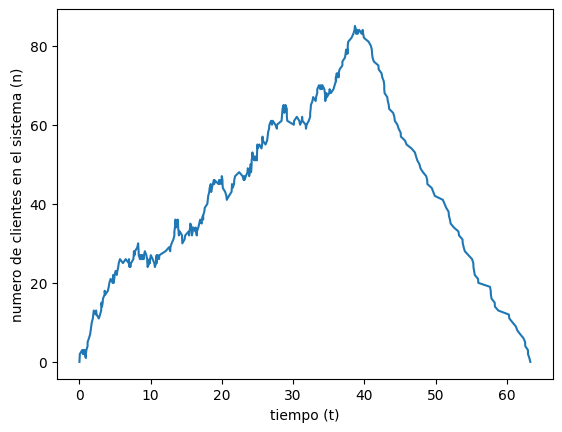

Tiempo medio de los clientes en el sistema:  13.210542864685985
Tiempo medio de los clientes en la cola:  12.897254000121281
Tiempo transcurrido desde T hasta que el último cliente abandona el sistema:  23.31295473811538
Número máximo de clientes en el sistema:  85
Total de clientes que pasaron por el sistema:  202


In [4]:
at = np.array(at)
an = np.array(an)

LLt = np.array(LLt)
St = np.array(St)

tmp = np.zeros((len(LLt)))+1

plt.plot(LLt, tmp, 'r.')
plt.xlim(0, max(at))
plt.show()

tmp = np.zeros((len(St)))+1

plt.plot(St, tmp, 'b.')
plt.xlim(0, max(at))
plt.show()

plt.plot(at,an)
plt.xlabel('tiempo (t)')
plt.ylabel('numero de clientes en el sistema (n)')
plt.show()

print("Tiempo medio de los clientes en el sistema: ",t_med_sistema)
print("Tiempo medio de los clientes en la cola: ",t_med_cola)
print("Tiempo transcurrido desde T hasta que el último cliente abandona el sistema: ",Tp)
print("Número máximo de clientes en el sistema: ",max(an))
print("Total de clientes que pasaron por el sistema: ",NLL)

### 10 repeticiones

In [5]:
T = 40.0
vlambda_llegada = 5
servicio = 'exponencial'
vlambda_servicio = 3

resultados = []

for rep in range(10):
    Xant1 = 434287492 + 1000*rep
    Xant2 = 5187324426 + 1000*rep
    np.random.seed(rep)

    at = []
    an = []
    LLt = []
    St = []

    t = tsuc = NLL = NS = n = 0

    at.append(t)
    an.append(n)

    TSuc = {"tLL":M, "tS":M}

    LL = []
    S = []
    Serv = []
    LL.append(0.0)
    S.append(0.0)
    Serv.append(0.0)

    X = GenerarX()

    if X > T:
        Tp = t_med_sistema = t_med_cola = 0.0
    else:
        Llegada(X)
        while((TSuc['tLL'] != M)|(TSuc['tS']!=M)):
            if TSuc['tLL'] < TSuc['tS']:
                tsuc = TSuc['tLL']
                TSuc['tLL'] = M
                Llegada(tsuc)

            if TSuc['tS'] < TSuc['tLL']:
                tsuc = TSuc['tS']
                TSuc['tS'] = M
                Servidor(tsuc)

        Tp = max(0,t-T)
        acumulo1 = acumulo2 = 0.0
        ind = 1                      # modificado: LL, S y Serv tienen un 0.0 de relleno en el indice 0

        while ind <= NLL:            # modificado: incluye al ultimo cliente
            acumulo1 = acumulo1 + S[ind] - LL[ind]
            acumulo2 = acumulo2 + S[ind] - LL[ind] - Serv[ind]
            ind = ind + 1
        t_med_sistema = acumulo1/NLL
        t_med_cola = acumulo2/NLL

    resultados.append([t_med_sistema, t_med_cola, Tp, max(an), NLL])

columnas = ['Tiempo medio en el sistema', 'Tiempo medio en la cola', 'Tp (desde T hasta que sale el último)',
            'Máximo de clientes en el sistema', 'Total de clientes']

gg1_A = pd.DataFrame(resultados, columns=columnas, index=range(1, 11))
gg1_A

,Tiempo medio en el sistema,Tiempo medio en la cola,Tp (desde T hasta que sale el último),Máximo de clientes en el sistema,Total de clientes
1,13.210543,12.897254,23.312955,85,202
2,14.317178,14.003755,26.562589,93,211
3,16.412584,16.058750,26.717512,90,187
4,13.194972,12.861694,25.731980,75,197
5,15.572746,15.239865,27.754716,96,201
6,20.170193,19.798894,36.865610,98,207
7,9.115656,8.813956,18.032765,69,192
8,15.980448,15.637816,29.526644,94,202
9,18.063016,17.722151,34.383066,106,218
10,15.638715,15.308116,32.062798,99,217


## Escenario B

T = 40 · tiempo entre llegadas ~ Exponencial(λ = 1) · tiempo de atención ~ Normal(μ = 2, σ = 1), valores negativos truncados a 0

### Ejecución única

In [6]:
T = 40.0
vlambda_llegada = 1
servicio = 'normal'
mu_servicio = 2
sigma_servicio = 1

Xant1 = 434287492
Xant2 = 5187324426

at = []
an = []
LLt = []
St = []

t = tsuc = NLL = NS = n = 0

at.append(t)
an.append(n)

TSuc = {"tLL":M, "tS":M}

LL = []
S = []
Serv = []
LL.append(0.0)
S.append(0.0)
Serv.append(0.0)

X = GenerarX()

if X > T:
    Tp = t_med_sistema = t_med_cola = 0.0
else:
    Llegada(X)
    while((TSuc['tLL'] != M)|(TSuc['tS']!=M)):
        if TSuc['tLL'] < TSuc['tS']:
            tsuc = TSuc['tLL']
            TSuc['tLL'] = M
            Llegada(tsuc)

        if TSuc['tS'] < TSuc['tLL']:
            tsuc = TSuc['tS']
            TSuc['tS'] = M
            Servidor(tsuc)

    Tp = max(0,t-T)
    acumulo1 = acumulo2 = 0.0
    ind = 1                      # modificado: LL, S y Serv tienen un 0.0 de relleno en el indice 0

    while ind <= NLL:            # modificado: incluye al ultimo cliente
        acumulo1 = acumulo1 + S[ind] - LL[ind]
        acumulo2 = acumulo2 + S[ind] - LL[ind] - Serv[ind]
        ind = ind + 1
    t_med_sistema = acumulo1/NLL
    t_med_cola = acumulo2/NLL

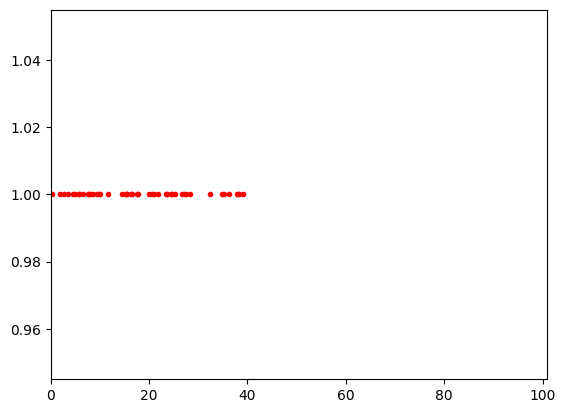

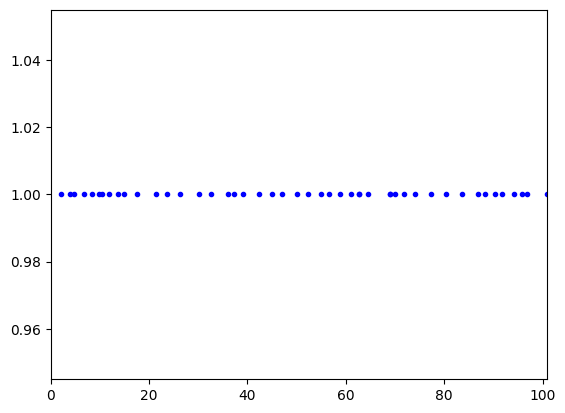

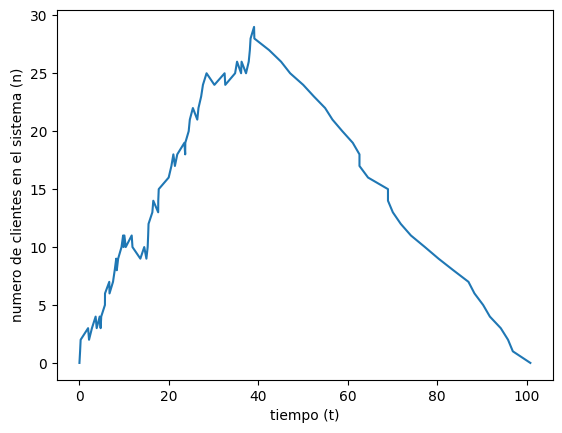

Tiempo medio de los clientes en el sistema:  32.002272047744675
Tiempo medio de los clientes en la cola:  29.86018536836357
Tiempo transcurrido desde T hasta que el último cliente abandona el sistema:  60.82109441114491
Número máximo de clientes en el sistema:  29
Total de clientes que pasaron por el sistema:  47


In [7]:
at = np.array(at)
an = np.array(an)

LLt = np.array(LLt)
St = np.array(St)

tmp = np.zeros((len(LLt)))+1

plt.plot(LLt, tmp, 'r.')
plt.xlim(0, max(at))
plt.show()

tmp = np.zeros((len(St)))+1

plt.plot(St, tmp, 'b.')
plt.xlim(0, max(at))
plt.show()

plt.plot(at,an)
plt.xlabel('tiempo (t)')
plt.ylabel('numero de clientes en el sistema (n)')
plt.show()

print("Tiempo medio de los clientes en el sistema: ",t_med_sistema)
print("Tiempo medio de los clientes en la cola: ",t_med_cola)
print("Tiempo transcurrido desde T hasta que el último cliente abandona el sistema: ",Tp)
print("Número máximo de clientes en el sistema: ",max(an))
print("Total de clientes que pasaron por el sistema: ",NLL)

### 10 repeticiones

In [8]:
T = 40.0
vlambda_llegada = 1
servicio = 'normal'
mu_servicio = 2
sigma_servicio = 1

resultados = []

for rep in range(10):
    Xant1 = 434287492 + 1000*rep
    Xant2 = 5187324426 + 1000*rep
    np.random.seed(rep)

    at = []
    an = []
    LLt = []
    St = []

    t = tsuc = NLL = NS = n = 0

    at.append(t)
    an.append(n)

    TSuc = {"tLL":M, "tS":M}

    LL = []
    S = []
    Serv = []
    LL.append(0.0)
    S.append(0.0)
    Serv.append(0.0)

    X = GenerarX()

    if X > T:
        Tp = t_med_sistema = t_med_cola = 0.0
    else:
        Llegada(X)
        while((TSuc['tLL'] != M)|(TSuc['tS']!=M)):
            if TSuc['tLL'] < TSuc['tS']:
                tsuc = TSuc['tLL']
                TSuc['tLL'] = M
                Llegada(tsuc)

            if TSuc['tS'] < TSuc['tLL']:
                tsuc = TSuc['tS']
                TSuc['tS'] = M
                Servidor(tsuc)

        Tp = max(0,t-T)
        acumulo1 = acumulo2 = 0.0
        ind = 1                      # modificado: LL, S y Serv tienen un 0.0 de relleno en el indice 0

        while ind <= NLL:            # modificado: incluye al ultimo cliente
            acumulo1 = acumulo1 + S[ind] - LL[ind]
            acumulo2 = acumulo2 + S[ind] - LL[ind] - Serv[ind]
            ind = ind + 1
        t_med_sistema = acumulo1/NLL
        t_med_cola = acumulo2/NLL

    resultados.append([t_med_sistema, t_med_cola, Tp, max(an), NLL])

columnas = ['Tiempo medio en el sistema', 'Tiempo medio en la cola', 'Tp (desde T hasta que sale el último)',
            'Máximo de clientes en el sistema', 'Total de clientes']

gg1_B = pd.DataFrame(resultados, columns=columnas, index=range(1, 11))
gg1_B

,Tiempo medio en el sistema,Tiempo medio en la cola,Tp (desde T hasta que sale el último),Máximo de clientes en el sistema,Total de clientes
1,40.186081,38.002462,62.773122,33,47
2,25.287065,23.360523,47.414308,25,45
3,23.235558,21.373256,47.902136,25,46
4,23.364347,21.615218,42.527989,26,47
5,13.808153,11.868132,30.579845,17,35
6,32.408603,30.299044,61.292381,30,48
7,12.649551,10.388265,28.371147,13,30
8,19.812673,17.884007,42.578197,22,42
9,32.913085,30.888343,53.327838,30,46
10,27.927221,25.800913,56.488450,27,45


## Tabla 1. Medidas de desempeño para los escenarios A y B luego de 10 simulaciones

In [9]:
tabla1 = pd.DataFrame({
    ('Escenario A', 'Promedio'): gg1_A.mean(),
    ('Escenario A', 'Desviación estándar'): gg1_A.std(ddof=1),
    ('Escenario B', 'Promedio'): gg1_B.mean(),
    ('Escenario B', 'Desviación estándar'): gg1_B.std(ddof=1),
}).round(3)
tabla1

Escenario A                      \
                                         Promedio Desviación estándar   
Tiempo medio en el sistema                 15.168               3.001   
Tiempo medio en la cola                    14.834               2.983   
Tp (desde T hasta que sale el último)      28.095               5.460   
Máximo de clientes en el sistema           90.500              11.306   
Total de clientes                         203.400              10.102   

                                      Escenario B                      
                                         Promedio Desviación estándar  
Tiempo medio en el sistema                 25.159               8.609  
Tiempo medio en la cola                    23.148               8.577  
Tp (desde T hasta que sale el último)      47.326              11.734  
Máximo de clientes en el sistema           24.800               6.106  
Total de clientes                          43.100               5.934